# MAGIC Gamma Telescope — TabICLv2 vs Random Forest trên CPU

**Dataset chính thức trên 10.000 dòng:** UCI MAGIC Gamma Telescope, **19.020 mẫu, 10 đặc trưng số**. Đây là dữ liệu sự kiện **mô phỏng Monte Carlo bằng CORSIKA**, không phải các quan sát kính thiên văn thực tế. Tải nguyên dataset chính thức từ UCI, không tự tạo mẫu hoặc ghép dữ liệu để tăng số dòng.

**Nhãn gốc:** `g` = gamma (signal), **12.332 mẫu**; `h` = hadron (background), **6.688 mẫu**. Ánh xạ cố định `g -> 1`, `h -> 0`; giữ `class` để truy vết. Chỉ đưa 10 đặc trưng vào X, **loại `row_id`, `class`, `target`**.

- Đặc trưng theo thứ tự gốc: `fLength`, `fWidth`, `fSize`, `fConc`, `fConc1`, `fAsym`, `fM3Long`, `fM3Trans`, `fAlpha`, `fDist`.
- Nguồn: https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope ; ZIP chính thức chứa `magic04.data` (không header, phân cách dấu phẩy).
- Trích dẫn: Bock, R. (2004). MAGIC Gamma Telescope [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52C8B — **CC BY 4.0**.
- **Cảnh báo của UCI:** Accuracy đơn thuần không đủ ý nghĩa khoa học: nhận nhầm hadron thành gamma (false positive) gây hậu quả lớn hơn bỏ sót gamma; tỷ lệ hadron trong dataset thấp hơn thực tế quan sát. Luôn xem **ROC/ROC-AUC** cùng Accuracy, macro-F1 và log loss.
- Toàn bộ AUC không chứng minh chất lượng tại một ngưỡng vận hành/FPR cụ thể. Không dùng test để chọn ngưỡng, cấu hình hay fold tốt nhất; validation được giữ riêng và chưa dùng tune.
- Dữ liệu, split, kết quả và biểu đồ lưu riêng trong namespace `magic_gamma_telescope`; không sửa các thực nghiệm trước.

## 1. Môi trường và cấu hình
Dùng kernel đã có các thư viện như notebook trước: `tabicl`, `torch`, `numpy`, `pandas`, `scikit-learn`, `certifi`, `threadpoolctl`; `matplotlib` cho biểu đồ. Chạy lần lượt từ trên xuống khi muốn thực nghiệm. **Pilot một seed**, train sizes 50, 100, 500, 1000, 5000 là số mẫu train, không phải tổng số dòng dataset.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import io
import json
import os
import platform
import ssl
import time
import urllib.request
import zipfile

N_CPU_THREADS = min(4, os.cpu_count() or 2)
os.environ['CUDA_VISIBLE_DEVICES'] = ''
os.environ['OMP_NUM_THREADS'] = str(N_CPU_THREADS)
os.environ['MKL_NUM_THREADS'] = str(N_CPU_THREADS)

import certifi
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if not (ROOT / 'datasets').is_dir():
    if (ROOT.parent / 'datasets').is_dir():
        ROOT = ROOT.parent
    else:
        raise FileNotFoundError('Mở notebook từ thư mục project hoặc notebooks.')
DATASET_ID = 'magic_gamma_telescope'
DATASET = ROOT / 'datasets' / f'{DATASET_ID}.csv'
SPLITS = ROOT / 'splits'
RESULTS = ROOT / 'results' / DATASET_ID
SPLITS.mkdir(exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
SEEDS = [42]
TRAIN_SIZES = [50, 100, 500, 1000, 5000]
CHECKPOINT = 'tabicl-classifier-v2-20260212.ckpt'
FEATURES = ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1',
            'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist']
CLASS_MAPPING = {'g': 1, 'h': 0}
SOURCE_URL = 'https://archive.ics.uci.edu/static/public/159/magic+gamma+telescope.zip'
SOURCE_MEMBER = 'magic04.data'
SPLIT_STRATEGY = 'stratified_group_5x5_first_fold_v1'
MODEL_IDS = ['RandomForest', 'TabICLv2']
RESULT_FILE = RESULTS / 'tabiclv2_vs_randomforest.csv'
ROC_FILE = RESULTS / 'roc_points.csv'
CONFIG_FILE = RESULTS / 'config.json'


def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return 'not_installed'


VERSIONS = {name: package_version(name) for name in
            ['numpy', 'pandas', 'scikit-learn', 'torch', 'tabicl',
             'threadpoolctl', 'certifi', 'matplotlib']}
print('Python:', platform.python_version(), '| CPU:', platform.machine(), '| threads:', N_CPU_THREADS)
print('Packages:', VERSIONS)
print('Kết quả riêng:', RESULTS)

Python: 3.14.6 | CPU: arm64 | threads: 4
Packages: {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'torch': '2.14.1', 'tabicl': '2.2.0', 'threadpoolctl': '3.7.0', 'certifi': '2026.7.22', 'matplotlib': '3.11.2'}
Kết quả riêng: /Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/results/magic_gamma_telescope


## 2. Tải nguồn chính thức, bảo toàn nhãn gốc và kiểm tra dữ liệu

Lần đầu tải ZIP từ UCI bằng TLS có xác minh chứng chỉ (`certifi`), đọc `magic04.data` không header với dấu phân cách `,`; các lần sau đọc CSV cục bộ. CSV gồm **19.020 dòng × 13 cột**: `row_id`, 10 đặc trưng, `class`, `target`. Kiểm tra giá trị hữu hạn, đúng số mẫu từng lớp và đúng toàn bộ ánh xạ nhãn.

Lưu SHA-256 của CSV và, khi tải mới, cả member dữ liệu gốc/ZIP cùng thời điểm tải trong cấu hình. Với CSV có sẵn mà thiếu provenance tương ứng, hash nguồn gốc được ghi `null`, không tự suy diễn hoặc tải lại âm thầm. Nhóm bản sao theo **đúng X float32 mà mô hình nhận được**, không theo nhãn.

In [2]:
def validate_frame(data):
    assert list(data.columns) == ['row_id', *FEATURES, 'class', 'target'], data.columns.tolist()
    assert data.shape == (19020, 13), data.shape
    assert data['row_id'].tolist() == list(range(19020))
    assert not data.isna().any().any(), 'Dữ liệu có giá trị thiếu'
    assert np.isfinite(data[FEATURES].to_numpy(dtype=float)).all(), 'Đặc trưng không hữu hạn'
    assert data['class'].value_counts().to_dict() == {'g': 12332, 'h': 6688}
    assert data['target'].equals(data['class'].map(CLASS_MAPPING).astype(int)), 'Ánh xạ nhãn không khớp'
    assert data['target'].value_counts().to_dict() == {1: 12332, 0: 6688}


SOURCE_PROVENANCE = dict(source_data_sha256=None, source_archive_sha256=None, downloaded_utc=None)
downloaded_now = not DATASET.exists()
if downloaded_now:
    print('Đang tải dataset chính thức từ UCI:', SOURCE_URL)
    context = ssl.create_default_context(cafile=certifi.where())
    with urllib.request.urlopen(SOURCE_URL, timeout=60, context=context) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as bundle:
        raw = bundle.read(SOURCE_MEMBER)
    downloaded = pd.read_csv(io.BytesIO(raw), header=None, sep=',', names=[*FEATURES, 'class'])
    downloaded.insert(0, 'row_id', np.arange(len(downloaded)))
    downloaded['target'] = downloaded['class'].map(CLASS_MAPPING).astype(int)
    validate_frame(downloaded)
    downloaded.to_csv(DATASET, index=False)
    SOURCE_PROVENANCE.update(
        source_data_sha256=hashlib.sha256(raw).hexdigest(),
        source_archive_sha256=hashlib.sha256(archive).hexdigest(),
        downloaded_utc=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
    )

frame = pd.read_csv(DATASET)
validate_frame(frame)
DATASET_SHA256 = hashlib.sha256(DATASET.read_bytes()).hexdigest()
if not downloaded_now and CONFIG_FILE.exists():
    previous = json.loads(CONFIG_FILE.read_text(encoding='utf-8'))
    if (previous.get('dataset_sha256') == DATASET_SHA256
            and previous.get('source_url') == SOURCE_URL
            and previous.get('source_member') == SOURCE_MEMBER):
        SOURCE_PROVENANCE = {key: previous.get(key) for key in SOURCE_PROVENANCE}
if downloaded_now:
    # Ghi provenance ngay để vẫn còn hash nguồn nếu dừng trước cell chạy mô hình.
    CONFIG_FILE.write_text(json.dumps({
        'dataset': DATASET_ID, 'dataset_sha256': DATASET_SHA256,
        'source_url': SOURCE_URL, 'source_member': SOURCE_MEMBER, **SOURCE_PROVENANCE,
    }, indent=2), encoding='utf-8')
if SOURCE_PROVENANCE['source_data_sha256'] is None:
    print('CSV cục bộ hợp lệ; chưa có hash member/ZIP gốc tương ứng (không tự tạo provenance).')

X = frame[FEATURES].to_numpy(dtype=np.float32)
y = frame['target'].to_numpy(dtype=np.int64)
assert np.isfinite(X).all()
assert not {'row_id', 'class', 'target'}.intersection(FEATURES)
GROUPS = pd.factorize(pd.MultiIndex.from_frame(pd.DataFrame(X, columns=FEATURES)), sort=False)[0]
N_GROUPS = int(np.unique(GROUPS).size)
print('Dataset:', DATASET_ID, '| mẫu:', len(y), '| đặc trưng:', X.shape[1])
print('Nhãn: gamma g -> 1 (signal); hadron h -> 0 (background)')
print('Số mẫu theo lớp:', {int(k): int(v) for k, v in zip(*np.unique(y, return_counts=True))})
print('Số nhóm X khác nhau:', N_GROUPS, '| số dòng đặc trưng trùng:', len(y) - N_GROUPS)
print('CSV SHA-256:', DATASET_SHA256)
display(frame.head())

Đang tải dataset chính thức từ UCI: https://archive.ics.uci.edu/static/public/159/magic+gamma+telescope.zip
Dataset: magic_gamma_telescope | mẫu: 19020 | đặc trưng: 10
Nhãn: gamma g -> 1 (signal); hadron h -> 0 (background)
Số mẫu theo lớp: {0: 6688, 1: 12332}
Số nhóm X khác nhau: 18905 | số dòng đặc trưng trùng: 115
CSV SHA-256: 3e871b9b32dec3fd5d55dd01304a2e1984eb72604f9a6d9cd43a404734527181


,row_id,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class,target
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g,1
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g,1
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g,1
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g,1
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g,1


## 3. Split theo nhóm và train subsets dùng chung

Dùng fold đầu của **StratifiedGroupKFold 5 folds** làm test (xấp xỉ 20%), rồi fold đầu của 5 folds trên phần còn lại làm validation (xấp xỉ 16% tổng số dòng). Phần còn lại là train pool. Tỷ lệ có thể lệch nhẹ để giữ nhóm nguyên vẹn; không chọn fold theo kết quả mô hình.

Lấy mẫu phân tầng độc lập các train sizes **50, 100, 500, 1000, 5000**; không giả định các tập con lồng nhau. Hai mô hình dùng **đúng cùng row IDs**, test cố định theo seed. Hỗ trợ cả trường hợp lấy toàn bộ train pool. Validation giữ riêng, **chưa dùng tune**; preprocessing của mô hình chỉ fit trên train.

Lưu chỉ số các tập, train subsets, SHA-256 dữ liệu và SHA-256 từng danh sách chỉ số trong `splits/magic_gamma_telescope_seed42.json`. Mỗi lần đọc đều kiểm tra đủ 19.020 chỉ số, không lặp/chồng lấn, đủ hai lớp và **nhóm X không giao nhau giữa train/validation/test**.

In [3]:
def indices_hash(values):
    return hashlib.sha256(json.dumps(list(map(int, values))).encode()).hexdigest()


def validate_indices(values):
    assert all(type(i) is int and 0 <= i < len(y) for i in values), 'Chỉ số không hợp lệ'
    assert len(set(values)) == len(values), 'Chỉ số trùng lặp'
    assert set(y[values]) == {0, 1}, 'Tập con phải có cả hai lớp'


def indices_for_seed(seed):
    path = SPLITS / f'{DATASET_ID}_seed{seed}.json'
    if path.exists():
        split = json.loads(path.read_text(encoding='utf-8'))
    else:
        outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        pool, test = next(outer.split(X, y, groups=GROUPS))
        inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        train_pos, val_pos = next(inner.split(X[pool], y[pool], groups=GROUPS[pool]))
        train, val = pool[train_pos], pool[val_pos]
        split = {'dataset': DATASET_ID, 'dataset_sha256': DATASET_SHA256, 'seed': seed,
                 'label_mapping': CLASS_MAPPING, 'strategy': SPLIT_STRATEGY,
                 'group_by': 'all_10_features_float32',
                 'train': sorted(map(int, train)), 'val': sorted(map(int, val)),
                 'test': sorted(map(int, test)), 'train_subsets': {}, 'train_subsets_sha256': {}}
        split['indices_sha256'] = {key: indices_hash(split[key]) for key in ['train', 'val', 'test']}
    assert split['seed'] == seed and split['dataset'] == DATASET_ID
    assert split['dataset_sha256'] == DATASET_SHA256, 'CSV đã thay đổi so với split'
    assert split['label_mapping'] == CLASS_MAPPING
    assert split['strategy'] == SPLIT_STRATEGY and split['group_by'] == 'all_10_features_float32'
    parts = [split[key] for key in ['train', 'val', 'test']]
    for key, part in zip(['train', 'val', 'test'], parts):
        validate_indices(part)
        assert split['indices_sha256'][key] == indices_hash(part), 'Hash chỉ số split không khớp'
    merged = [i for part in parts for i in part]
    assert len(merged) == len(set(merged)) == len(y), 'Split bị chồng lặp hoặc thiếu mẫu'
    assert set(merged) == set(range(len(y)))
    group_sets = [set(GROUPS[part].tolist()) for part in parts]
    for i in range(len(group_sets)):
        for j in range(i + 1, len(group_sets)):
            assert group_sets[i].isdisjoint(group_sets[j]), 'Rò rỉ bản sao giữa các tập'
    path.write_text(json.dumps(split, indent=2), encoding='utf-8')
    return split, path


def make_fold(seed, n):
    split, path = indices_for_seed(seed)
    pool = np.asarray(split['train'], dtype=int)
    if not isinstance(n, int) or not 2 <= n <= len(pool):
        raise ValueError(f'n_train={n} không nằm trong [2, {len(pool)}]')
    subsets = split['train_subsets']
    if str(n) not in subsets:
        if n == len(pool):
            chosen = pool
        else:
            chosen, _ = train_test_split(pool, train_size=n, stratify=y[pool],
                                         random_state=seed + 101)
        subsets[str(n)] = sorted(map(int, chosen))
        split['train_subsets_sha256'][str(n)] = indices_hash(subsets[str(n)])
    chosen = subsets[str(n)]
    validate_indices(chosen)
    assert len(chosen) == n and set(chosen).issubset(split['train'])
    assert split['train_subsets_sha256'][str(n)] == indices_hash(chosen), 'Hash train subset không khớp'
    path.write_text(json.dumps(split, indent=2), encoding='utf-8')
    return X[chosen], y[chosen], X[split['test']], y[split['test']], chosen, split


def metrics(y_true, prob, classes):
    classes = np.asarray(classes)
    p = np.asarray(prob, dtype=float)
    assert classes.shape == (2,) and set(classes.tolist()) == {0, 1}, classes
    assert p.shape == (len(y_true), 2), p.shape
    assert np.isfinite(p).all() and (p >= 0).all() and (p <= 1).all(), 'Xác suất không hợp lệ'
    assert np.allclose(p.sum(axis=1), 1.0, atol=1e-5), 'Tổng xác suất không bằng 1'
    p = p[:, [int(np.flatnonzero(classes == label)[0]) for label in [0, 1]]]
    pred = np.argmax(p, axis=1)
    auc = roc_auc_score(y_true, p[:, 1])
    p = np.clip(p, 1e-8, 1.0)
    p = p / p.sum(axis=1, keepdims=True)
    return {'accuracy': accuracy_score(y_true, pred),
            'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0),
            'roc_auc': auc, 'log_loss': log_loss(y_true, p, labels=[0, 1])}


for seed in SEEDS:
    for n in TRAIN_SIZES:
        xtr, ytr, xte, yte, chosen, split = make_fold(seed, n)
        assert len(ytr) == n and xtr.shape[1] == len(FEATURES)
        print(f'seed={seed}: train pool={len(split["train"])}, train dùng={n}, '
              f'val={len(split["val"])}, test={len(yte)}, train_hash={indices_hash(chosen)[:12]}')
print('Đã xác thực: không có vector đặc trưng trùng giữa train, validation và test.')

seed=42: train pool=12172, train dùng=50, val=3044, test=3804, train_hash=eac26298b1e2
seed=42: train pool=12172, train dùng=100, val=3044, test=3804, train_hash=cab2bbc4a6a1
seed=42: train pool=12172, train dùng=500, val=3044, test=3804, train_hash=9ec7870a8da0
seed=42: train pool=12172, train dùng=1000, val=3044, test=3804, train_hash=1e43fdb3c46e
seed=42: train pool=12172, train dùng=5000, val=3044, test=3804, train_hash=f920dcc34232
Đã xác thực: không có vector đặc trưng trùng giữa train, validation và test.


## 4. Chạy TabICLv2 và Random Forest

Giữ cấu hình đối chứng CPU như thực nghiệm trước: **TabICLv2** checkpoint cố định `tabicl-classifier-v2-20260212.ckpt`, `n_estimators=1`, `batch_size=1`, tắt AMP/FA3, `offload_mode='auto'`; **Random Forest** 300 cây, các siêu tham số khác theo mặc định. Cả hai dùng tối đa 4 luồng và cùng seed, không tuning bằng test. Nạp Torch và đặt số luồng **trước** khi áp giới hạn threadpool.

TabICLv2 đã pretrain; thời gian `fit` ở đây không phải pretraining, có thể chứa cold-start tải/nạp checkpoint. Random Forest học từ đầu. Chưa đo peak RAM; không diễn giải đây là cùng tổng chi phí học. Train size 5000 và test vài nghìn dòng có thể tốn nhiều thời gian/RAM trên CPU.

Mỗi lượt ghi kết quả và các điểm ROC ngay vào CSV, kèm hash train/test, trạng thái và lỗi. Chỉ thu ROC **sau khi các metric được tính thành công**, dùng xác suất của `classes_ == 1` (gamma). Lỗi từng lượt được ghi `failed`, không chặn mô hình còn lại và không thay mô hình/checkpoint giả. Chạy lại cell sẽ ghi lại riêng kết quả MAGIC theo cấu hình hiện tại.

In [4]:
TABICL_PARAMS = dict(device='cpu', n_estimators=1, batch_size=1,
                     use_amp=False, use_fa3=False, offload_mode='auto',
                     checkpoint_version=CHECKPOINT, n_jobs=N_CPU_THREADS)
RF_PARAMS = dict(n_estimators=300, n_jobs=N_CPU_THREADS)

# Nạp Torch trước mọi threadpool_limits, kể cả lượt RF đầu tiên.
# Nếu Torch không khả dụng, RF vẫn chạy; TabICLv2 ghi lỗi thật cho từng lượt.
TORCH_INIT_ERROR = ''
try:
    import torch
    torch.set_num_threads(N_CPU_THREADS)
except Exception as exc:
    TORCH_INIT_ERROR = repr(exc)[:1600]
    print('Torch initialization failed:', TORCH_INIT_ERROR)

RUN_CONFIG = {
    'dataset': DATASET_ID, 'dataset_sha256': DATASET_SHA256,
    'source_url': SOURCE_URL, 'source_member': SOURCE_MEMBER, **SOURCE_PROVENANCE,
    'dataset_page': 'https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope',
    'citation': 'Bock, R. (2004). MAGIC Gamma Telescope. UCI Machine Learning Repository.',
    'doi': '10.24432/C52C8B', 'license': 'CC BY 4.0',
    'data_origin': 'CORSIKA Monte Carlo simulated events; not real telescope observations',
    'label_mapping': CLASS_MAPPING, 'positive_class': 1, 'positive_class_name': 'gamma (signal)',
    'excluded_columns': ['row_id', 'class', 'target'],
    'n_samples': len(y), 'features': FEATURES, 'seeds': SEEDS, 'train_sizes': TRAIN_SIZES,
    'raw_class_counts': {str(k): int(v) for k, v in frame['class'].value_counts().items()},
    'target_counts': {str(k): int(v) for k, v in frame['target'].value_counts().items()},
    'n_feature_groups': N_GROUPS, 'split_strategy': SPLIT_STRATEGY,
    'group_by': 'all_10_features_float32', 'validation_used': False, 'test_tuning': False,
    'nominal_test_fraction': 0.2, 'nominal_validation_fraction_of_remaining': 0.2,
    'split_counts': {str(seed): {key: len(indices_for_seed(seed)[0][key])
                               for key in ['train', 'val', 'test']} for seed in SEEDS},
    'tabicl_params': TABICL_PARAMS, 'randomforest_params': RF_PARAMS,
    'random_state_per_model': 'same seed for both models in each run',
    'python': platform.python_version(), 'platform': platform.platform(),
    'cpu_threads': N_CPU_THREADS, 'package_versions': VERSIONS,
    'torch_initialization_error': TORCH_INIT_ERROR,
    'timing_note': 'fit may include checkpoint download/loading, not pretraining; predict is predict_proba only',
    'scientific_caveat': 'Hadron false positives are more costly; background prevalence is underestimated; full AUC is not an operating-threshold guarantee.',
    'started_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
}
CONFIG_FILE.write_text(json.dumps(RUN_CONFIG, indent=2), encoding='utf-8')


def build_model(model_id, seed):
    if model_id == 'RandomForest':
        return RandomForestClassifier(**RF_PARAMS, random_state=seed)
    if model_id == 'TabICLv2':
        if TORCH_INIT_ERROR:
            raise RuntimeError(f'Torch initialization failed: {TORCH_INIT_ERROR}')
        from tabicl import TabICLClassifier

        return TabICLClassifier(**TABICL_PARAMS, random_state=seed)
    raise ValueError(f'Mô hình không được hỗ trợ: {model_id}')


# Tránh để biểu đồ/bảng tổng hợp cũ bị hiểu nhầm là kết quả lần chạy mới.
for artifact in ['summary.csv', 'metrics.png', 'timing.png', 'roc.png']:
    (RESULTS / artifact).unlink(missing_ok=True)
ROC_COLUMNS = ['dataset', 'dataset_sha256', 'model', 'seed', 'train_size',
               'train_indices_sha256', 'test_indices_sha256',
               'point_index', 'fpr', 'tpr', 'threshold']
rows, roc_rows = [], []
for seed in SEEDS:
    for n in TRAIN_SIZES:
        for model_id in MODEL_IDS:
            row = {'model': model_id, 'dataset': DATASET_ID, 'seed': seed,
                   'train_size': n, 'test_size': np.nan, 'status': 'failed',
                   **{key: np.nan for key in ['accuracy', 'macro_f1', 'roc_auc', 'log_loss',
                                              'fit_seconds', 'predict_seconds']},
                   'package_version': VERSIONS['tabicl' if model_id == 'TabICLv2' else 'scikit-learn'],
                   'checkpoint': CHECKPOINT if model_id == 'TabICLv2' else '',
                   'cpu_threads': N_CPU_THREADS, 'dataset_sha256': DATASET_SHA256,
                   'positive_class': 1, 'split_strategy': SPLIT_STRATEGY,
                   'train_indices_sha256': '', 'test_indices_sha256': '', 'error': '',
                   'started_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())}
            print(f'Đang chạy {model_id}: seed={seed}, train={n}', flush=True)
            try:
                xtr, ytr, xte, yte, chosen, split = make_fold(seed, n)
                row['test_size'] = len(yte)
                row['train_indices_sha256'] = indices_hash(chosen)
                row['test_indices_sha256'] = indices_hash(split['test'])
                model = build_model(model_id, seed)
                with threadpool_limits(limits=N_CPU_THREADS):
                    started = time.perf_counter()
                    model.fit(xtr, ytr)
                    row['fit_seconds'] = time.perf_counter() - started
                    started = time.perf_counter()
                    prob = model.predict_proba(xte)
                    row['predict_seconds'] = time.perf_counter() - started
                row.update(metrics(yte, prob, model.classes_))
                # Chỉ thu ROC sau khi metric/xác suất đã được xác thực thành công.
                gamma_prob = np.asarray(prob)[:, np.asarray(model.classes_) == 1].ravel()
                fpr, tpr, thresholds = roc_curve(yte, gamma_prob, pos_label=1)
                roc_rows.extend([
                    {'dataset': DATASET_ID, 'dataset_sha256': DATASET_SHA256,
                     'model': model_id, 'seed': seed, 'train_size': n,
                     'train_indices_sha256': row['train_indices_sha256'],
                     'test_indices_sha256': row['test_indices_sha256'],
                     'point_index': point, 'fpr': float(fp), 'tpr': float(tp), 'threshold': float(threshold)}
                    for point, (fp, tp, threshold) in enumerate(zip(fpr, tpr, thresholds))
                ])
                row['status'] = 'ok'
                print(f'  accuracy={row["accuracy"]:.4f}, macro_f1={row["macro_f1"]:.4f}, '
                      f'AUC={row["roc_auc"]:.4f}, fit={row["fit_seconds"]:.3f}s, '
                      f'predict={row["predict_seconds"]:.3f}s', flush=True)
                del model
            except Exception as exc:
                row['error'] = repr(exc)[:1600]
                print('  FAILED:', row['error'], flush=True)
            row['finished_utc'] = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
            rows.append(row)
            pd.DataFrame(rows).to_csv(RESULT_FILE, index=False)
            pd.DataFrame(roc_rows, columns=ROC_COLUMNS).to_csv(ROC_FILE, index=False)

runs = pd.DataFrame(rows)
RUN_CONFIG['finished_utc'] = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
CONFIG_FILE.write_text(json.dumps(RUN_CONFIG, indent=2), encoding='utf-8')
print('Đã lưu:', RESULT_FILE, 'và', ROC_FILE)
display(runs[['model', 'seed', 'train_size', 'test_size', 'status', 'accuracy', 'macro_f1',
              'roc_auc', 'log_loss', 'fit_seconds', 'predict_seconds', 'error']])

Đang chạy RandomForest: seed=42, train=50
  accuracy=0.7892, macro_f1=0.7568, AUC=0.8502, fit=0.164s, predict=0.026s
Đang chạy TabICLv2: seed=42, train=50


/Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  accuracy=0.7855, macro_f1=0.7562, AUC=0.8521, fit=0.302s, predict=0.644s
Đang chạy RandomForest: seed=42, train=100
  accuracy=0.8212, macro_f1=0.7906, AUC=0.8758, fit=0.119s, predict=0.025s
Đang chạy TabICLv2: seed=42, train=100
  accuracy=0.8141, macro_f1=0.7912, AUC=0.8711, fit=0.096s, predict=0.835s
Đang chạy RandomForest: seed=42, train=500
  accuracy=0.8407, macro_f1=0.8220, AUC=0.9003, fit=0.137s, predict=0.026s
Đang chạy TabICLv2: seed=42, train=500
  accuracy=0.8701, macro_f1=0.8548, AUC=0.9270, fit=0.133s, predict=0.876s
Đang chạy RandomForest: seed=42, train=1000
  accuracy=0.8528, macro_f1=0.8337, AUC=0.9073, fit=0.207s, predict=0.051s
Đang chạy TabICLv2: seed=42, train=1000
  accuracy=0.8757, macro_f1=0.8603, AUC=0.9333, fit=0.126s, predict=0.889s
Đang chạy RandomForest: seed=42, train=5000
  accuracy=0.8651, macro_f1=0.8484, AUC=0.9221, fit=0.547s, predict=0.037s
Đang chạy TabICLv2: seed=42, train=5000
  accuracy=0.8933, macro_f1=0.8809, AUC=0.9455, fit=0.091s, predict=

,model,seed,train_size,test_size,status,accuracy,macro_f1,roc_auc,log_loss,fit_seconds,predict_seconds,error
0,RandomForest,42,50,3804,ok,0.789169,0.756789,0.850210,0.462692,0.164359,0.025717,
1,TabICLv2,42,50,3804,ok,0.785489,0.756225,0.852134,0.500348,0.301974,0.643727,
2,RandomForest,42,100,3804,ok,0.821241,0.790557,0.875849,0.428041,0.119399,0.024622,
3,TabICLv2,42,100,3804,ok,0.814143,0.791198,0.871108,0.435171,0.095557,0.834895,
4,RandomForest,42,500,3804,ok,0.840694,0.822026,0.900258,0.379817,0.137287,0.025926,
5,TabICLv2,42,500,3804,ok,0.870137,0.854753,0.927004,0.324204,0.132667,0.876088,
6,RandomForest,42,1000,3804,ok,0.852787,0.833724,0.907313,0.357750,0.206520,0.050779,
7,TabICLv2,42,1000,3804,ok,0.875657,0.860252,0.933331,0.302951,0.126397,0.889219,
8,RandomForest,42,5000,3804,ok,0.865142,0.848374,0.922063,0.326812,0.546926,0.036932,
9,TabICLv2,42,5000,3804,ok,0.893270,0.880899,0.945548,0.271693,0.091326,3.494817,


## 5. Tổng hợp, ROC và biểu đồ cho báo cáo

Chỉ tổng hợp/vẽ **cặp cùng seed/train size có cả hai mô hình thành công**, cùng hash train/test và cùng hash dữ liệu. Đọc lại kết quả và `roc_points.csv` từ đĩa: không chỉ vẽ ROC của lượt cuối và không cần giữ các mô hình trong RAM. Sau khi đã có kết quả, có thể chạy phần môi trường/dữ liệu rồi cell tổng hợp mà không fit lại.

Xuất `summary.csv`, `metrics.png`, `timing.png` và **`roc.png` gồm một panel cho mỗi train size** (mặc định 5 panel trên lưới 2×3). Mỗi đường có model/seed/AUC; đường chéo là mức ngẫu nhiên. Trục FPR là **hadron bị nhận nhầm thành gamma**; TPR là gamma được nhận đúng. Các điểm ROC dùng để vẽ, **không dùng test chọn ngưỡng**; ngưỡng đầu có thể là `inf` theo API ROC.

Accuracy/macro-F1 ở đây dùng argmax xác suất, không phải một ngưỡng vận hành được tối ưu cho thiên văn học. UCI lưu ý false positive của background nghiêm trọng và background thực tế nhiều hơn dataset; **cả Accuracy lẫn toàn bộ AUC không đủ chứng minh hiệu quả triển khai**. Cần xem vùng FPR quan tâm và một protocol ngưỡng/chi phí riêng ngoài test nếu nghiên cứu tiếp.

Đây là pilot **một seed**, không kết luận ưu thế toàn cục; std là NaN với một seed, không có nghĩa biến thiên bằng 0. Có thể mở rộng `SEEDS` rồi chạy lại từ đầu. Không so trực tiếp Accuracy giữa dataset này và các dataset khác để suy ra mô hình tốt hơn. Chi phí pretraining và peak RAM chưa được tính.

Trạng thái các lượt chạy:


,model,status,n_runs
0,RandomForest,ok,5
1,TabICLv2,ok,5


Kết quả trên đúng cùng train/test:


,model,seed,train_size,test_size,accuracy,macro_f1,roc_auc,log_loss,fit_seconds,predict_seconds
0,RandomForest,42,50,3804,0.789169,0.756789,0.850210,0.462692,0.164359,0.025717
1,TabICLv2,42,50,3804,0.785489,0.756225,0.852134,0.500348,0.301974,0.643727
2,RandomForest,42,100,3804,0.821241,0.790557,0.875849,0.428041,0.119399,0.024622
3,TabICLv2,42,100,3804,0.814143,0.791198,0.871108,0.435171,0.095557,0.834895
4,RandomForest,42,500,3804,0.840694,0.822026,0.900258,0.379817,0.137287,0.025926
5,TabICLv2,42,500,3804,0.870137,0.854753,0.927004,0.324204,0.132667,0.876088
6,RandomForest,42,1000,3804,0.852787,0.833724,0.907313,0.357750,0.206520,0.050779
7,TabICLv2,42,1000,3804,0.875657,0.860252,0.933331,0.302951,0.126397,0.889219
8,RandomForest,42,5000,3804,0.865142,0.848374,0.922063,0.326812,0.546926,0.036932
9,TabICLv2,42,5000,3804,0.893270,0.880899,0.945548,0.271693,0.091326,3.494817


Mean/std/count (std cần ít nhất 2 seed):


,model,train_size,accuracy_mean,accuracy_std,accuracy_count,macro_f1_mean,macro_f1_std,macro_f1_count,roc_auc_mean,roc_auc_std,roc_auc_count,log_loss_mean,log_loss_std,log_loss_count,fit_seconds_mean,fit_seconds_std,fit_seconds_count,predict_seconds_mean,predict_seconds_std,predict_seconds_count
0,RandomForest,50,0.789169,NaN,1,0.756789,NaN,1,0.850210,NaN,1,0.462692,NaN,1,0.164359,NaN,1,0.025717,NaN,1
1,RandomForest,100,0.821241,NaN,1,0.790557,NaN,1,0.875849,NaN,1,0.428041,NaN,1,0.119399,NaN,1,0.024622,NaN,1
2,RandomForest,500,0.840694,NaN,1,0.822026,NaN,1,0.900258,NaN,1,0.379817,NaN,1,0.137287,NaN,1,0.025926,NaN,1
3,RandomForest,1000,0.852787,NaN,1,0.833724,NaN,1,0.907313,NaN,1,0.357750,NaN,1,0.206520,NaN,1,0.050779,NaN,1
4,RandomForest,5000,0.865142,NaN,1,0.848374,NaN,1,0.922063,NaN,1,0.326812,NaN,1,0.546926,NaN,1,0.036932,NaN,1
5,TabICLv2,50,0.785489,NaN,1,0.756225,NaN,1,0.852134,NaN,1,0.500348,NaN,1,0.301974,NaN,1,0.643727,NaN,1
6,TabICLv2,100,0.814143,NaN,1,0.791198,NaN,1,0.871108,NaN,1,0.435171,NaN,1,0.095557,NaN,1,0.834895,NaN,1
7,TabICLv2,500,0.870137,NaN,1,0.854753,NaN,1,0.927004,NaN,1,0.324204,NaN,1,0.132667,NaN,1,0.876088,NaN,1
8,TabICLv2,1000,0.875657,NaN,1,0.860252,NaN,1,0.933331,NaN,1,0.302951,NaN,1,0.126397,NaN,1,0.889219,NaN,1
9,TabICLv2,5000,0.893270,NaN,1,0.880899,NaN,1,0.945548,NaN,1,0.271693,NaN,1,0.091326,NaN,1,3.494817,NaN,1


model            RandomForest  TabICLv2  TabICLv2_minus_RF_percentage_points
seed train_size                                                             
42   50                0.7892    0.7855                              -0.3680
     100               0.8212    0.8141                              -0.7098
     500               0.8407    0.8701                               2.9443
     1000              0.8528    0.8757                               2.2871
     5000              0.8651    0.8933                               2.8128

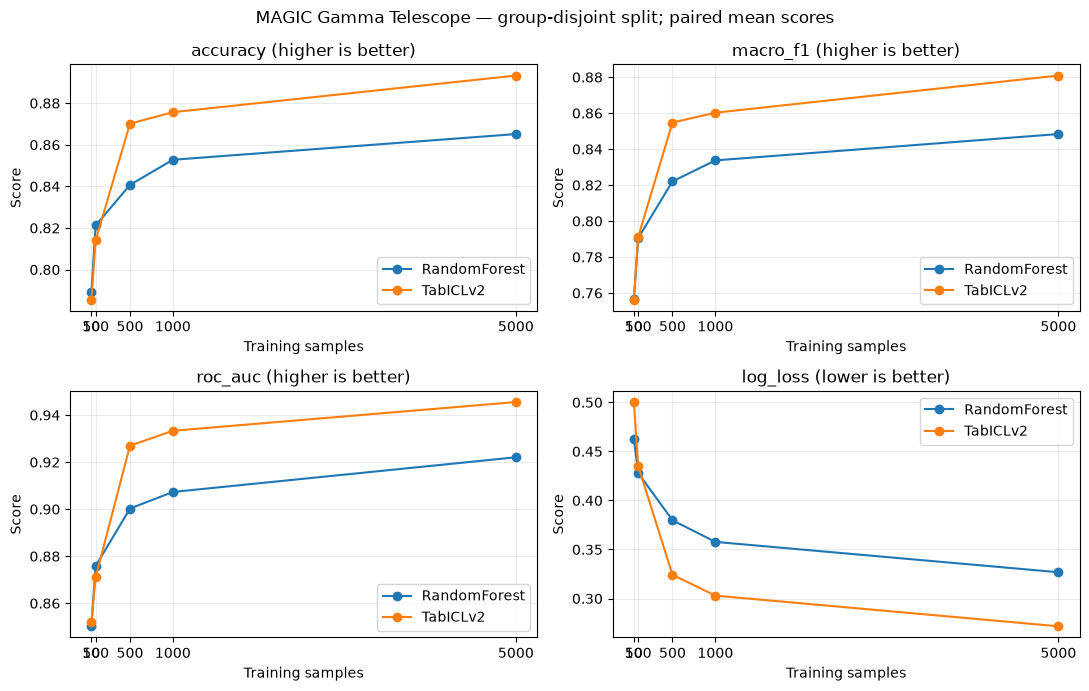

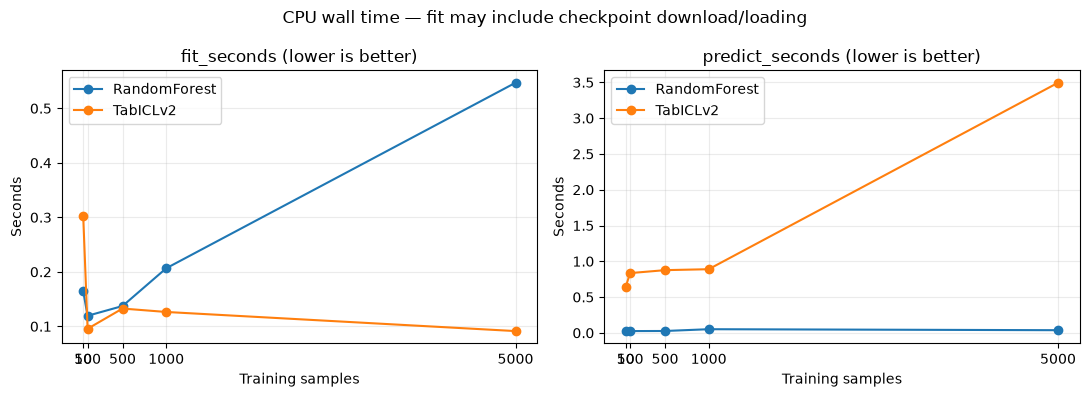

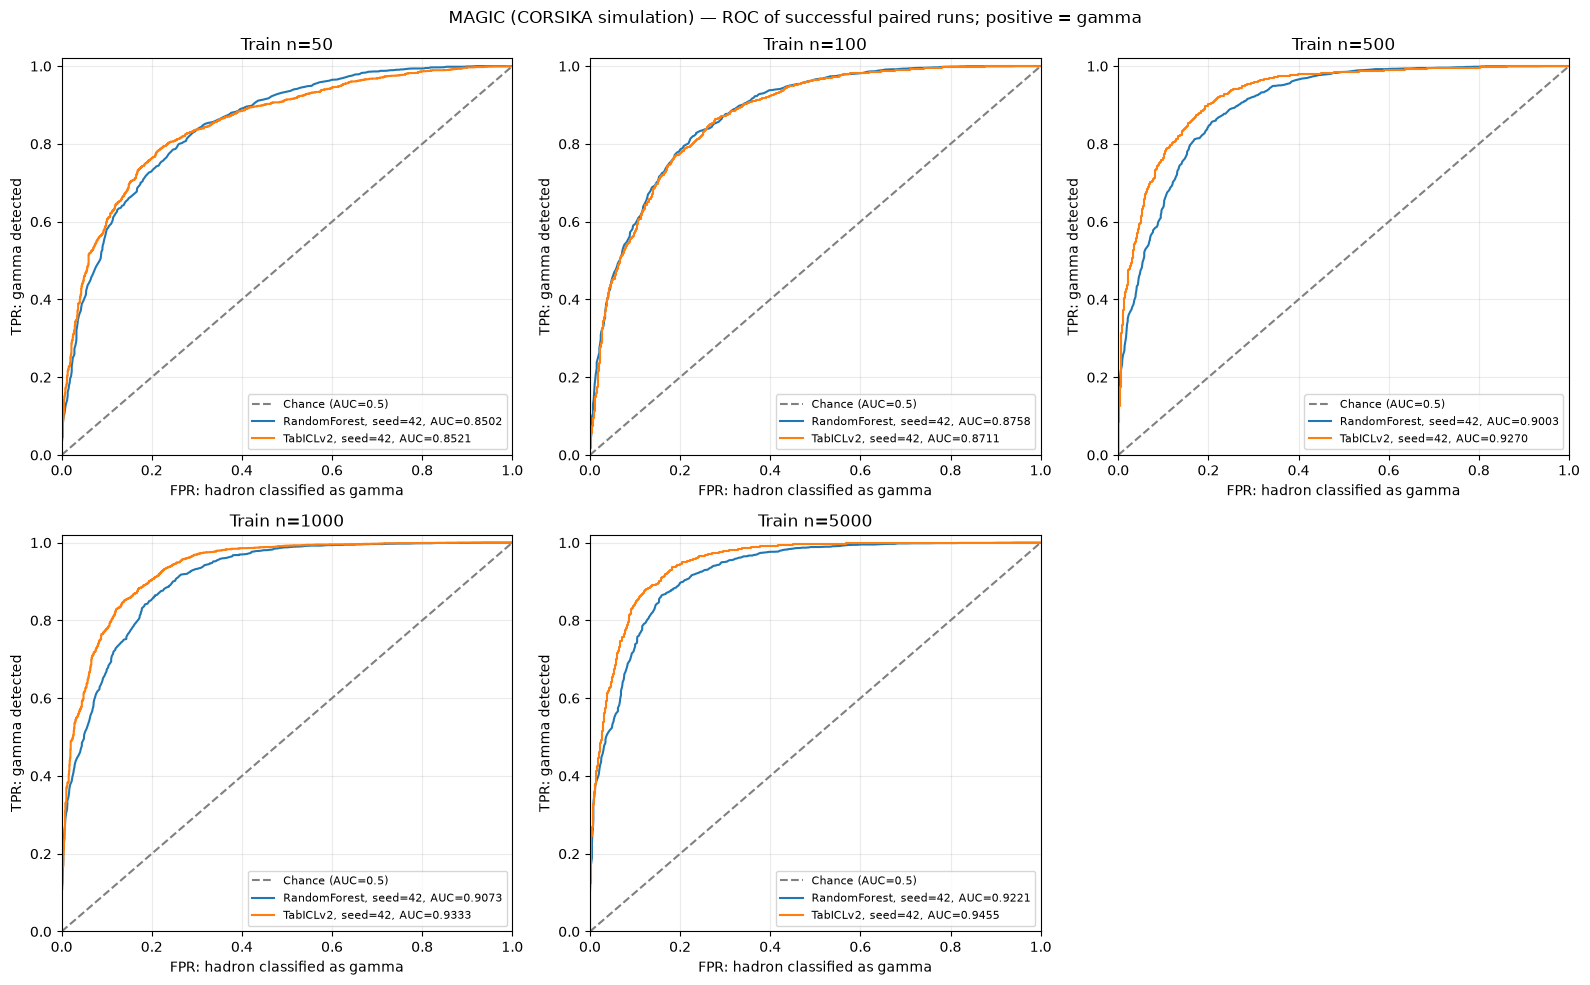

Bảng tổng hợp: /Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/results/magic_gamma_telescope/summary.csv


In [5]:
runs = pd.read_csv(RESULT_FILE)
assert not runs.duplicated(['model', 'seed', 'train_size']).any()
assert runs['dataset'].eq(DATASET_ID).all()
assert runs['dataset_sha256'].eq(DATASET_SHA256).all()
assert runs['positive_class'].eq(1).all()
assert runs['split_strategy'].eq(SPLIT_STRATEGY).all()
assert set(runs['model']).issubset(MODEL_IDS)
print('Trạng thái các lượt chạy:')
display(runs.groupby(['model', 'status']).size().rename('n_runs').reset_index())

successful = runs.loc[runs['status'].eq('ok')].copy()
paired = successful.groupby(['seed', 'train_size']).filter(
    lambda group: set(group['model']) == set(MODEL_IDS)
)
for _, group in paired.groupby(['seed', 'train_size']):
    assert group['train_indices_sha256'].notna().all() and group['train_indices_sha256'].nunique() == 1
    assert group['test_indices_sha256'].notna().all() and group['test_indices_sha256'].nunique() == 1
    assert group['test_size'].nunique() == 1

SCORE_KEYS = ['accuracy', 'macro_f1', 'roc_auc', 'log_loss']
TIME_KEYS = ['fit_seconds', 'predict_seconds']
SUMMARY_FILE = RESULTS / 'summary.csv'
for artifact in ['metrics.png', 'timing.png', 'roc.png']:
    (RESULTS / artifact).unlink(missing_ok=True)
summary = paired.groupby(['model', 'train_size'])[SCORE_KEYS + TIME_KEYS].agg(['mean', 'std', 'count'])
summary.columns = ['_'.join(column) for column in summary.columns]
summary = summary.reset_index()
summary.to_csv(SUMMARY_FILE, index=False)
if paired.empty:
    print('Chưa có cặp thành công. Xem error, không suy diễn kết quả.')
    display(runs.loc[runs['status'].ne('ok'), ['model', 'seed', 'train_size', 'error']])
else:
    print('Kết quả trên đúng cùng train/test:')
    display(paired[['model', 'seed', 'train_size', 'test_size', *SCORE_KEYS, *TIME_KEYS]].round(6))
    print('Mean/std/count (std cần ít nhất 2 seed):')
    display(summary.round(6))
    accuracy_table = paired.pivot(index=['seed', 'train_size'], columns='model', values='accuracy')
    accuracy_table['TabICLv2_minus_RF_percentage_points'] = (
        accuracy_table['TabICLv2'] - accuracy_table['RandomForest']
    ) * 100
    display(accuracy_table.round(4))

    # CSV có thể chứa ROC của lượt thành công đơn lẻ; chỉ chọn các cặp thành công.
    roc_points = pd.read_csv(ROC_FILE)
    curve_keys = ['model', 'seed', 'train_size']
    assert not roc_points.duplicated([*curve_keys, 'point_index']).any()
    assert roc_points['dataset'].eq(DATASET_ID).all()
    assert roc_points['dataset_sha256'].eq(DATASET_SHA256).all()
    match_keys = [*curve_keys, 'dataset_sha256', 'train_indices_sha256', 'test_indices_sha256']
    paired_roc = roc_points.merge(paired[match_keys], on=match_keys, how='inner', validate='many_to_one')
    assert set(paired_roc[curve_keys].drop_duplicates().itertuples(index=False, name=None)) == set(
        paired[curve_keys].itertuples(index=False, name=None)
    ), 'Thiếu ROC tương ứng với cặp thành công; không vẽ ROC cũ/khác split'
    for _, curve in paired_roc.groupby(curve_keys):
        curve = curve.sort_values('point_index')
        assert curve['point_index'].tolist() == list(range(len(curve)))
        values = curve[['fpr', 'tpr']].to_numpy(dtype=float)
        assert np.isfinite(values).all() and (values >= 0).all() and (values <= 1).all()
        assert (np.diff(values, axis=0) >= -1e-12).all()
        assert np.allclose(values[0], [0, 0]) and np.allclose(values[-1], [1, 1])

    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print('Chưa có matplotlib: CSV đã được lưu; cần matplotlib để xuất biểu đồ.')
    else:
        means = paired.groupby(['model', 'train_size'])[SCORE_KEYS + TIME_KEYS].mean()
        for filename, keys, shape in [('metrics.png', SCORE_KEYS, (2, 2)),
                                      ('timing.png', TIME_KEYS, (1, 2))]:
            fig, axes = plt.subplots(*shape, figsize=(11, 7 if len(keys) == 4 else 4))
            for ax, metric in zip(np.asarray(axes).ravel(), keys):
                for model_id in MODEL_IDS:
                    values = means.loc[model_id, metric].sort_index()
                    ax.plot(values.index, values.to_numpy(), marker='o', label=model_id)
                ax.set_title(metric + (' (higher is better)' if metric in SCORE_KEYS[:3]
                                      else ' (lower is better)'))
                ax.set_xlabel('Training samples')
                ax.set_ylabel('Seconds' if metric in TIME_KEYS else 'Score')
                ax.set_xticks(sorted(paired['train_size'].unique()))
                ax.grid(alpha=0.25)
                ax.legend()
            fig.suptitle('MAGIC Gamma Telescope — group-disjoint split; paired mean scores'
                         if filename == 'metrics.png' else
                         'CPU wall time — fit may include checkpoint download/loading')
            fig.tight_layout()
            fig.savefig(RESULTS / filename, dpi=180, bbox_inches='tight')
            plt.show()
            plt.close(fig)

        sizes = sorted(runs['train_size'].unique().tolist())
        ncols = 3
        nrows = (len(sizes) + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(16, 5 * nrows), squeeze=False)
        colors = {'RandomForest': 'tab:blue', 'TabICLv2': 'tab:orange'}
        auc_by_run = paired.set_index(curve_keys)['roc_auc']
        for ax, n in zip(axes.ravel(), sizes):
            panel = paired_roc.loc[paired_roc['train_size'].eq(n)]
            ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance (AUC=0.5)')
            for (model_id, seed), curve in panel.groupby(['model', 'seed']):
                curve = curve.sort_values('point_index')
                auc = auc_by_run.loc[(model_id, seed, n)]
                ax.plot(curve['fpr'], curve['tpr'], color=colors[model_id],
                        label=f'{model_id}, seed={seed}, AUC={auc:.4f}')
            if panel.empty:
                ax.text(0.5, 0.4, 'No successful pair', ha='center', transform=ax.transAxes)
            ax.set_title(f'Train n={n}')
            ax.set_xlabel('FPR: hadron classified as gamma')
            ax.set_ylabel('TPR: gamma detected')
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.02)
            ax.grid(alpha=0.25)
            ax.legend(loc='lower right', fontsize=8)
        for ax in axes.ravel()[len(sizes):]:
            ax.set_visible(False)
        fig.suptitle('MAGIC (CORSIKA simulation) — ROC of successful paired runs; positive = gamma')
        fig.tight_layout()
        fig.savefig(RESULTS / 'roc.png', dpi=180, bbox_inches='tight')
        plt.show()
        plt.close(fig)
print('Bảng tổng hợp:', SUMMARY_FILE)